# ERA5-pretrained and from-scratch runs vs. global conventional obs

Compares forecast error against the same conventional-obs verification for three training
chains, all under

`/pscratch/sd/b/bhuang95/nested-eagle/0.25deg-06km/production/era5-gfs-hrrr/stage2c/diagnostics/`

| experiment | model | obs-metrics file tag |
|---|---|---|
| `inference-era5-gfs-hrrr-stage1a` | global, 1.00° grid | `convobs.global` |
| `inference-era5-gfs-hrrr-stage1b` | global, 0.25° grid | `convobs.global` |
| `inference-era5-gfs-hrrr-stage2a/2b/2c` | nested cutout (GFS + HRRR), ERA5-pretrained | `convobs.nested-global` |
| `inference-gfs-hrrr-stage1a/1b/1c` | nested cutout (GFS + HRRR), no ERA5 pretraining | `convobs.nested-global` |
| `inference-gfs-only-stage1a/1b/1c` | global (GFS only), no ERA5 pretraining | `convobs.global` |

**Three things to know before reading the plots.**

1. **The file tag differs by experiment.** The two ERA5 stage-1 runs and all three gfs-only
   runs write `*.convobs.global*.nc`; the ERA5 stage-2 runs and all three gfs-hrrr runs are
   nested-cutout models and write `*.convobs.nested-global*.nc`. The loader below picks the
   right tag per experiment, which is why a single f-string will not work.
2. **Color is the stage, linestyle is the run.** `2a`/`1a` share a color, `2b`/`1b` share a
   color, `2c`/`1c` share a color; era5-gfs-hrrr is solid, gfs-hrrr dashed, gfs-only
   dash-dot. So a vertical read of the legend compares training stages and a horizontal one
   compares training chains. The ERA5 stage-1a/1b runs have no counterpart in the other two
   chains and keep their own orange/red.
3. **The variable sets differ.** Only `era5-gfs-hrrr 1a`/`1b` omit `geopotential_height` and
   `2m_specific_humidity` — those ERA5 checkpoints carry `geopotential` (m²/s²) with no
   conversion in the obs registry, and have no 2 m humidity variable. The main figures
   therefore plot only variables **common to all eleven**; the two missing variables get
   their own section at the end, over the nine runs that carry them.

Curves are drawn without the bootstrap confidence band (`errorbar=None`) — with eleven
series the shading buried the lines.

All eleven share the same verification period (113 inits, 2017-02-01T06 → 2018-01-31T06,
78 h apart), the same 61 lead times out to 360 h, and the same 4 pressure levels, so the
curves are directly comparable.


In [11]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import seaborn as sns
import xarray as xr

# niceplots.py lives in the shared baselines directory, not next to this notebook
NICEPLOTS_DIR = os.path.abspath("../../../../../baselines")
if NICEPLOTS_DIR not in sys.path:
    sys.path.insert(0, NICEPLOTS_DIR)

import niceplots
from niceplots import plot_surface_vars, plot_level_vars, nice_names, get_units

# ~/nice.mplstyle is not present on Perlmutter; fall back rather than raising
try:
    plt.style.use("~/nice.mplstyle")
except OSError:
    plt.rcParams.update({
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.grid": True,
        "grid.color": "#e6e5e1",   # recessive grid
        "grid.linewidth": 0.8,
        "axes.edgecolor": "#c3c2b7",
        "axes.linewidth": 0.8,
        "lines.linewidth": 2.0,
        "font.size": 12,
    })

In [12]:
DIAGDIR = "/pscratch/sd/b/bhuang95/nested-eagle/0.25deg-06km/production/era5-gfs-hrrr/stage2c/diagnostics"
FIGDIR = "figures-stage2a"
os.makedirs(FIGDIR, exist_ok=True)

# label -> (experiment directory, obs-metrics file tag)
# The tag is NOT the same for every run: plain global grids wrote `global`, nested cutout
# grids wrote `nested-global`.
EXPERIMENTS = {
    # GFS + HRRR nested cutout, trained from scratch
    "gfs-hrrr-s1a[tp: 8, mlr: 1e-3]": ("inference-gfs-hrrr_bo-stage1a", "nested-global"),
    # ERA5-pretrained chain
    "era5-gfs-hrrr-s2a[tp: 0, mlr: 1e-4]": ("inference-era5-gfs-hrrr-stage2a", "nested-global"),
    "era5-gfs-hrrr-s2a[tp: 8, mlr: 1e-3]": ("inference-era5-gfs-hrrr-stage2a_t1", "nested-global"),
    "era5-gfs-hrrr-s2a[tp: 8, mlr: 5e-4]": ("inference-era5-gfs-hrrr-stage2a_t2", "nested-global"),
}

# All three runs carry the full variable set, so this is the same as EXPERIMENTS.
FULL_VARSET = dict(EXPERIMENTS)

# "" is the global evaluation; the others are the subregions obs-metrics wrote
SUBREGIONS = ["", ".northern_hemisphere", ".southern_hemisphere", ".tropics", ".conus", ".europe"]
#SUBREGIONS = [".europe"]
SUBREGION = ""   # the one the interactive figures below use


In [13]:
# One color per experiment, all solid lines. Keys must match the EXPERIMENTS labels exactly —
# a label missing here falls back to matplotlib's default color cycle.
STYLE = {
    "gfs-hrrr-s1a[tp: 8, mlr: 1e-3]":              ("black", "-"),
    "era5-gfs-hrrr-s2a[tp: 0, mlr: 1e-4]":         ("blue",   "-"),
    "era5-gfs-hrrr-s2a[tp: 8, mlr: 1e-3]": ("green",  "-"),
    "era5-gfs-hrrr-s2a[tp: 8, mlr: 5e-4]": ("red",  "-"),
}


In [14]:
def single_plot(ax, dsdict, metric_name, varname, sel=None, **kwargs):
    """Same as niceplots.single_plot, plus a per-series linestyle.

    niceplots.single_plot colors by substring match in get_color(), which returns one
    color for every label here, and it has no second visual channel. Patching it in is
    cleaner than forking the whole module: plot_surface_vars and plot_level_vars look this
    name up in the niceplots namespace at call time, so they pick up this version and keep
    their own layout and legend handling.

    The shaded band is seaborn's 95% bootstrap CI over inits (t0), as in the era5 notebook.
    Pass errorbar=None to drop it for a single figure.
    """
    estimator = kwargs.pop("estimator", "median")
    errorbar = kwargs.pop("errorbar", ("ci", 95))
    for label, xds in dsdict.items():
        plotme = xds[varname] if sel is None else xds[varname].sel(**sel)
        df = plotme.to_dataframe().reset_index()
        color, linestyle = STYLE.get(label, (None, "-"))
        sns.lineplot(
            data=df,
            x="fhr",
            y=varname,
            ax=ax,
            label=label,
            color=color,
            linestyle=linestyle,
            estimator=estimator,
            #errorbar=errorbar,
            **kwargs,
        )
    xticks = plotme.fhr.values
    xticklabels = [str(xx) for xx in xticks]
    xlabel = "Lead Time (hours)"
    if len(xticks) > 10:
        xticks = np.concatenate([[xticks[0]], xticks[4::4]])
        xticklabels = [str(int(xx / 24)) for xx in xticks]
        xlabel = "Lead Time (days)"

    ax.set(
        ylabel=metric_name if ax.get_subplotspec().is_first_col() else "",
        xlabel=xlabel if ax.get_subplotspec().is_last_row() else "",
        title=f"{nice_names(varname)}  ({get_units(varname)})" if ax.get_subplotspec().is_first_row() else "",
        xticks=xticks,
        xticklabels=xticklabels,
    )
    ax.legend(frameon=False)


def make_one_legend(fig, axs, ncols=None):
    """niceplots.make_one_legend, laid out as a colour x linestyle grid.

    The original puts every series on one row and draws the keys at linewidth 16, which is
    wide enough to hide a dash pattern — with eleven series both have to change. Here each
    legend *column* is one colour (one stage) and each *row* is one linestyle (one run), so
    the legend itself shows the encoding. matplotlib fills a legend column-major, so the
    grid is flattened that way; empty slots are invisible spacers.
    """
    axs = np.asarray(axs)
    handles, labels = axs.flatten()[0].get_legend_handles_labels()

    # (row, col) = (linestyle, colour), in the order STYLE declares them
    colors = list(dict.fromkeys(c for c, _ in STYLE.values()))
    linestyles = list(dict.fromkeys(ls for _, ls in STYLE.values()))
    slots = {}
    for handle, label in zip(handles, labels):
        color, linestyle = STYLE.get(label, (None, "-"))
        if color in colors and linestyle in linestyles:
            slots[(linestyles.index(linestyle), colors.index(color))] = (handle, label)
    if len(slots) != len(labels):        # a label outside STYLE: fall back to one flat row
        slots = {(0, i): (h, l) for i, (h, l) in enumerate(zip(handles, labels))}

    rows = sorted({r for r, _ in slots})
    cols = sorted({c for _, c in slots})
    blank = mlines.Line2D([], [], linestyle="none")
    ordered = [slots.get((r, c), (blank, "")) for c in cols for r in rows]
    handles, labels = zip(*ordered)

    legend = fig.legend(
        handles,
        labels,
        loc="lower center",
        # the offset has to be in figure fractions but should be a fixed physical gap:
        # a 4-row pressure-level figure is four times as tall as a surface one
        bbox_to_anchor=(0.5, -(0.28 * len(rows) + 0.15) / fig.get_figheight()),
        ncols=len(cols) if ncols is None else ncols,
        frameon=False,
        handlelength=3.5,          # long enough for "-." to read as dash-dot
        columnspacing=1.4,
    )
    for line in legend.get_lines():
        line.set_linewidth(3)
    for ax in axs.flatten():
        ax.legend().remove()
    return legend


niceplots.single_plot = single_plot
niceplots.make_one_legend = make_one_legend


In [15]:
def load(metric, subregion=SUBREGION, experiments=EXPERIMENTS):
    """Load one metric for every experiment, handling the per-stage file tag."""
    out = {}
    for label, (subdir, tag) in experiments.items():
        path = f"{DIAGDIR}/{subdir}/obs-metrics/{metric}.convobs.{tag}{subregion}.nc"
        out[label] = xr.load_dataset(path, decode_timedelta=True)
    return out


def common_vars(dsdict, candidates):
    """Keep only the candidate variables present in *every* dataset, in order."""
    shared = set.intersection(*(set(ds.data_vars) for ds in dsdict.values()))
    return tuple(v for v in candidates if v in shared)


SURFACE_CANDIDATES = ("surface_pressure", "10m_wind_speed", "2m_temperature", "2m_specific_humidity")
LEVEL_CANDIDATES = ("geopotential_height", "wind_speed", "temperature", "specific_humidity")

In [16]:
rmse = load("rmse")
mae = load("mae")

SURFACE_VARS = common_vars(rmse, SURFACE_CANDIDATES)
LEVEL_VARS = common_vars(rmse, LEVEL_CANDIDATES)

for label, ds in rmse.items():
    missing = sorted(set(SURFACE_CANDIDATES + LEVEL_CANDIDATES) - set(ds.data_vars))
    print(f"{label:>18}: {ds.sizes['t0']} inits, fhr {ds.fhr.values[0]}-{ds.fhr.values[-1]}h, "
          f"levels {list(ds.level.values)}" + (f", missing {missing}" if missing else ""))

print(f"\nplotting surface vars: {SURFACE_VARS}")
print(f"plotting level vars:   {LEVEL_VARS}")


gfs-hrrr-s1a[tp: 8, mlr: 1e-3]: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]
era5-gfs-hrrr-s2a[tp: 0, mlr: 1e-4]: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]
era5-gfs-hrrr-s2a[tp: 8, mlr: 1e-3]: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]
era5-gfs-hrrr-s2a[tp: 8, mlr: 5e-4]: 113 inits, fhr 0-360h, levels [np.int64(100), np.int64(250), np.int64(500), np.int64(850)]

plotting surface vars: ('surface_pressure', '10m_wind_speed', '2m_temperature', '2m_specific_humidity')
plotting level vars:   ('geopotential_height', 'wind_speed', 'temperature', 'specific_humidity')


## Surface variables

Text(0.5, 1.06, 'RMSE vs conventional obs — mean over inits (global)')

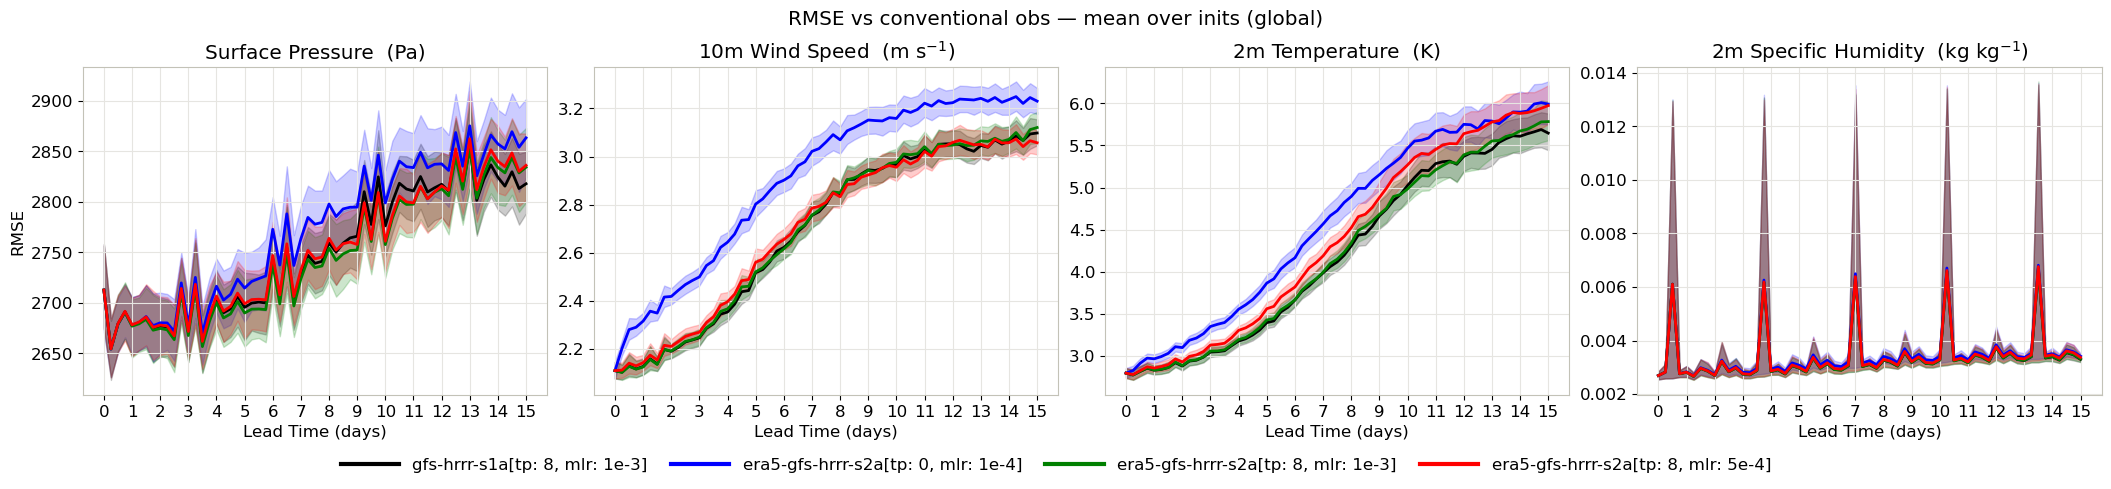

In [17]:
fig, axs = plot_surface_vars(rmse, metric_name="RMSE", surface_vars=SURFACE_VARS, estimator="mean")
fig.suptitle(f"RMSE vs conventional obs — mean over inits ({SUBREGION.lstrip('.') or 'global'})", y=1.06)

Text(0.5, 1.06, 'RMSE vs conventional obs — median over inits (global)')

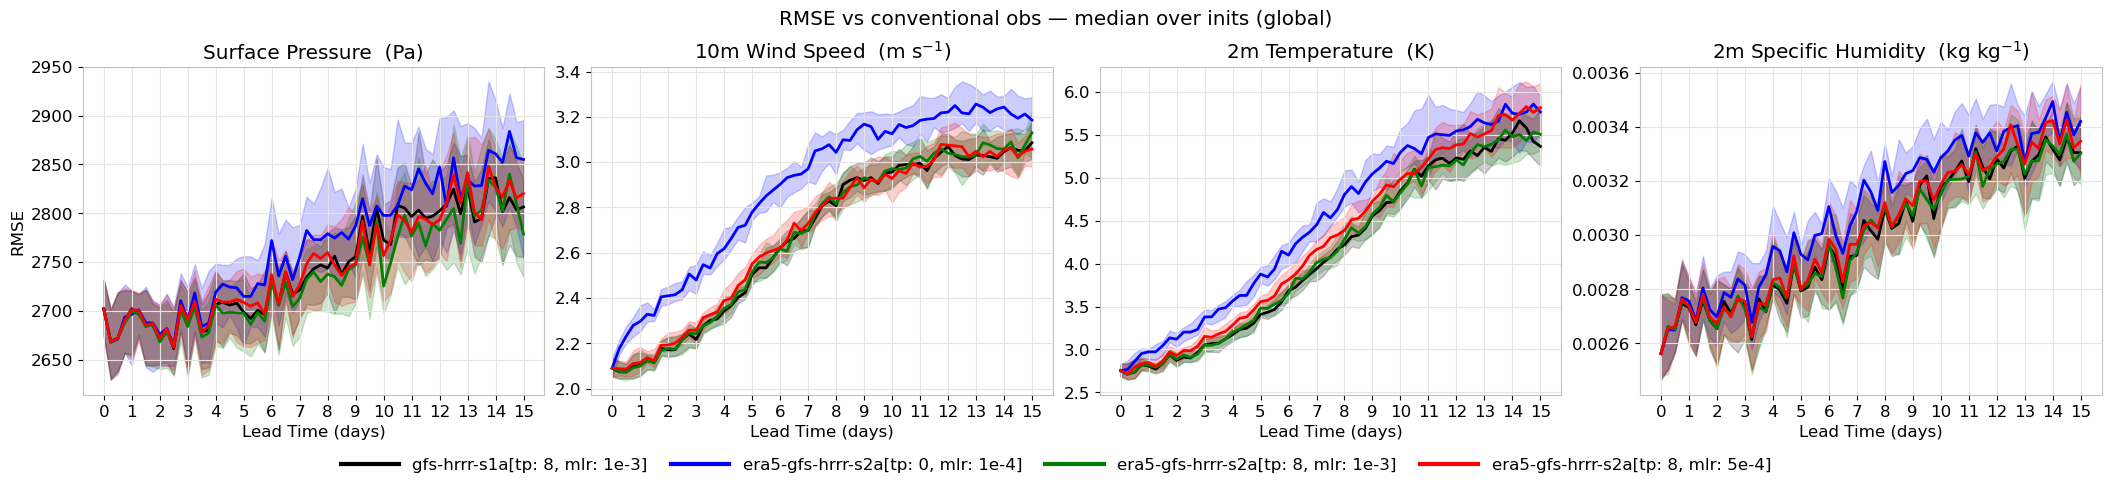

In [18]:
fig, axs = plot_surface_vars(rmse, metric_name="RMSE", surface_vars=SURFACE_VARS)
fig.suptitle(f"RMSE vs conventional obs — median over inits ({SUBREGION.lstrip('.') or 'global'})", y=1.06)

Text(0.5, 1.06, 'MAE vs conventional obs — median over inits (global)')

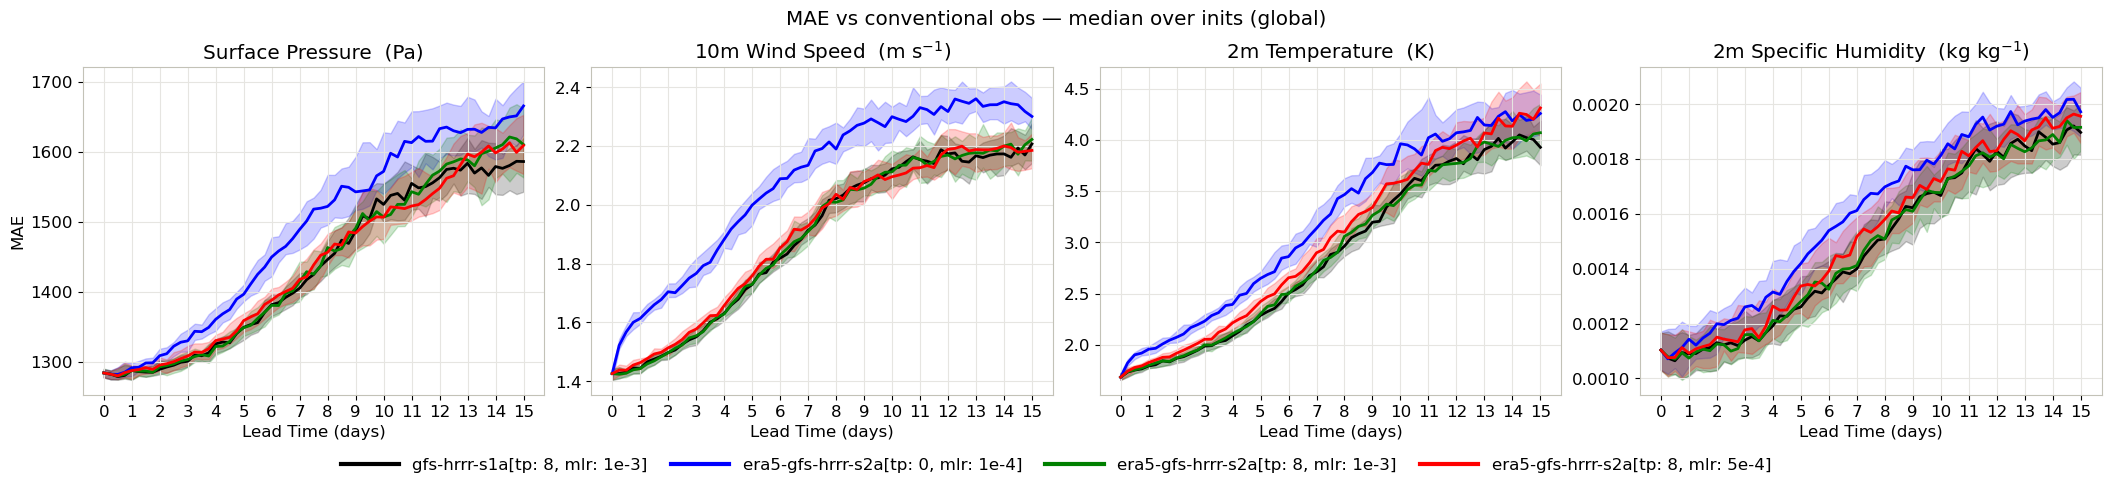

In [19]:
fig, axs = plot_surface_vars(mae, metric_name="MAE", surface_vars=SURFACE_VARS)
fig.suptitle(f"MAE vs conventional obs — median over inits ({SUBREGION.lstrip('.') or 'global'})", y=1.06)

## Pressure-level variables

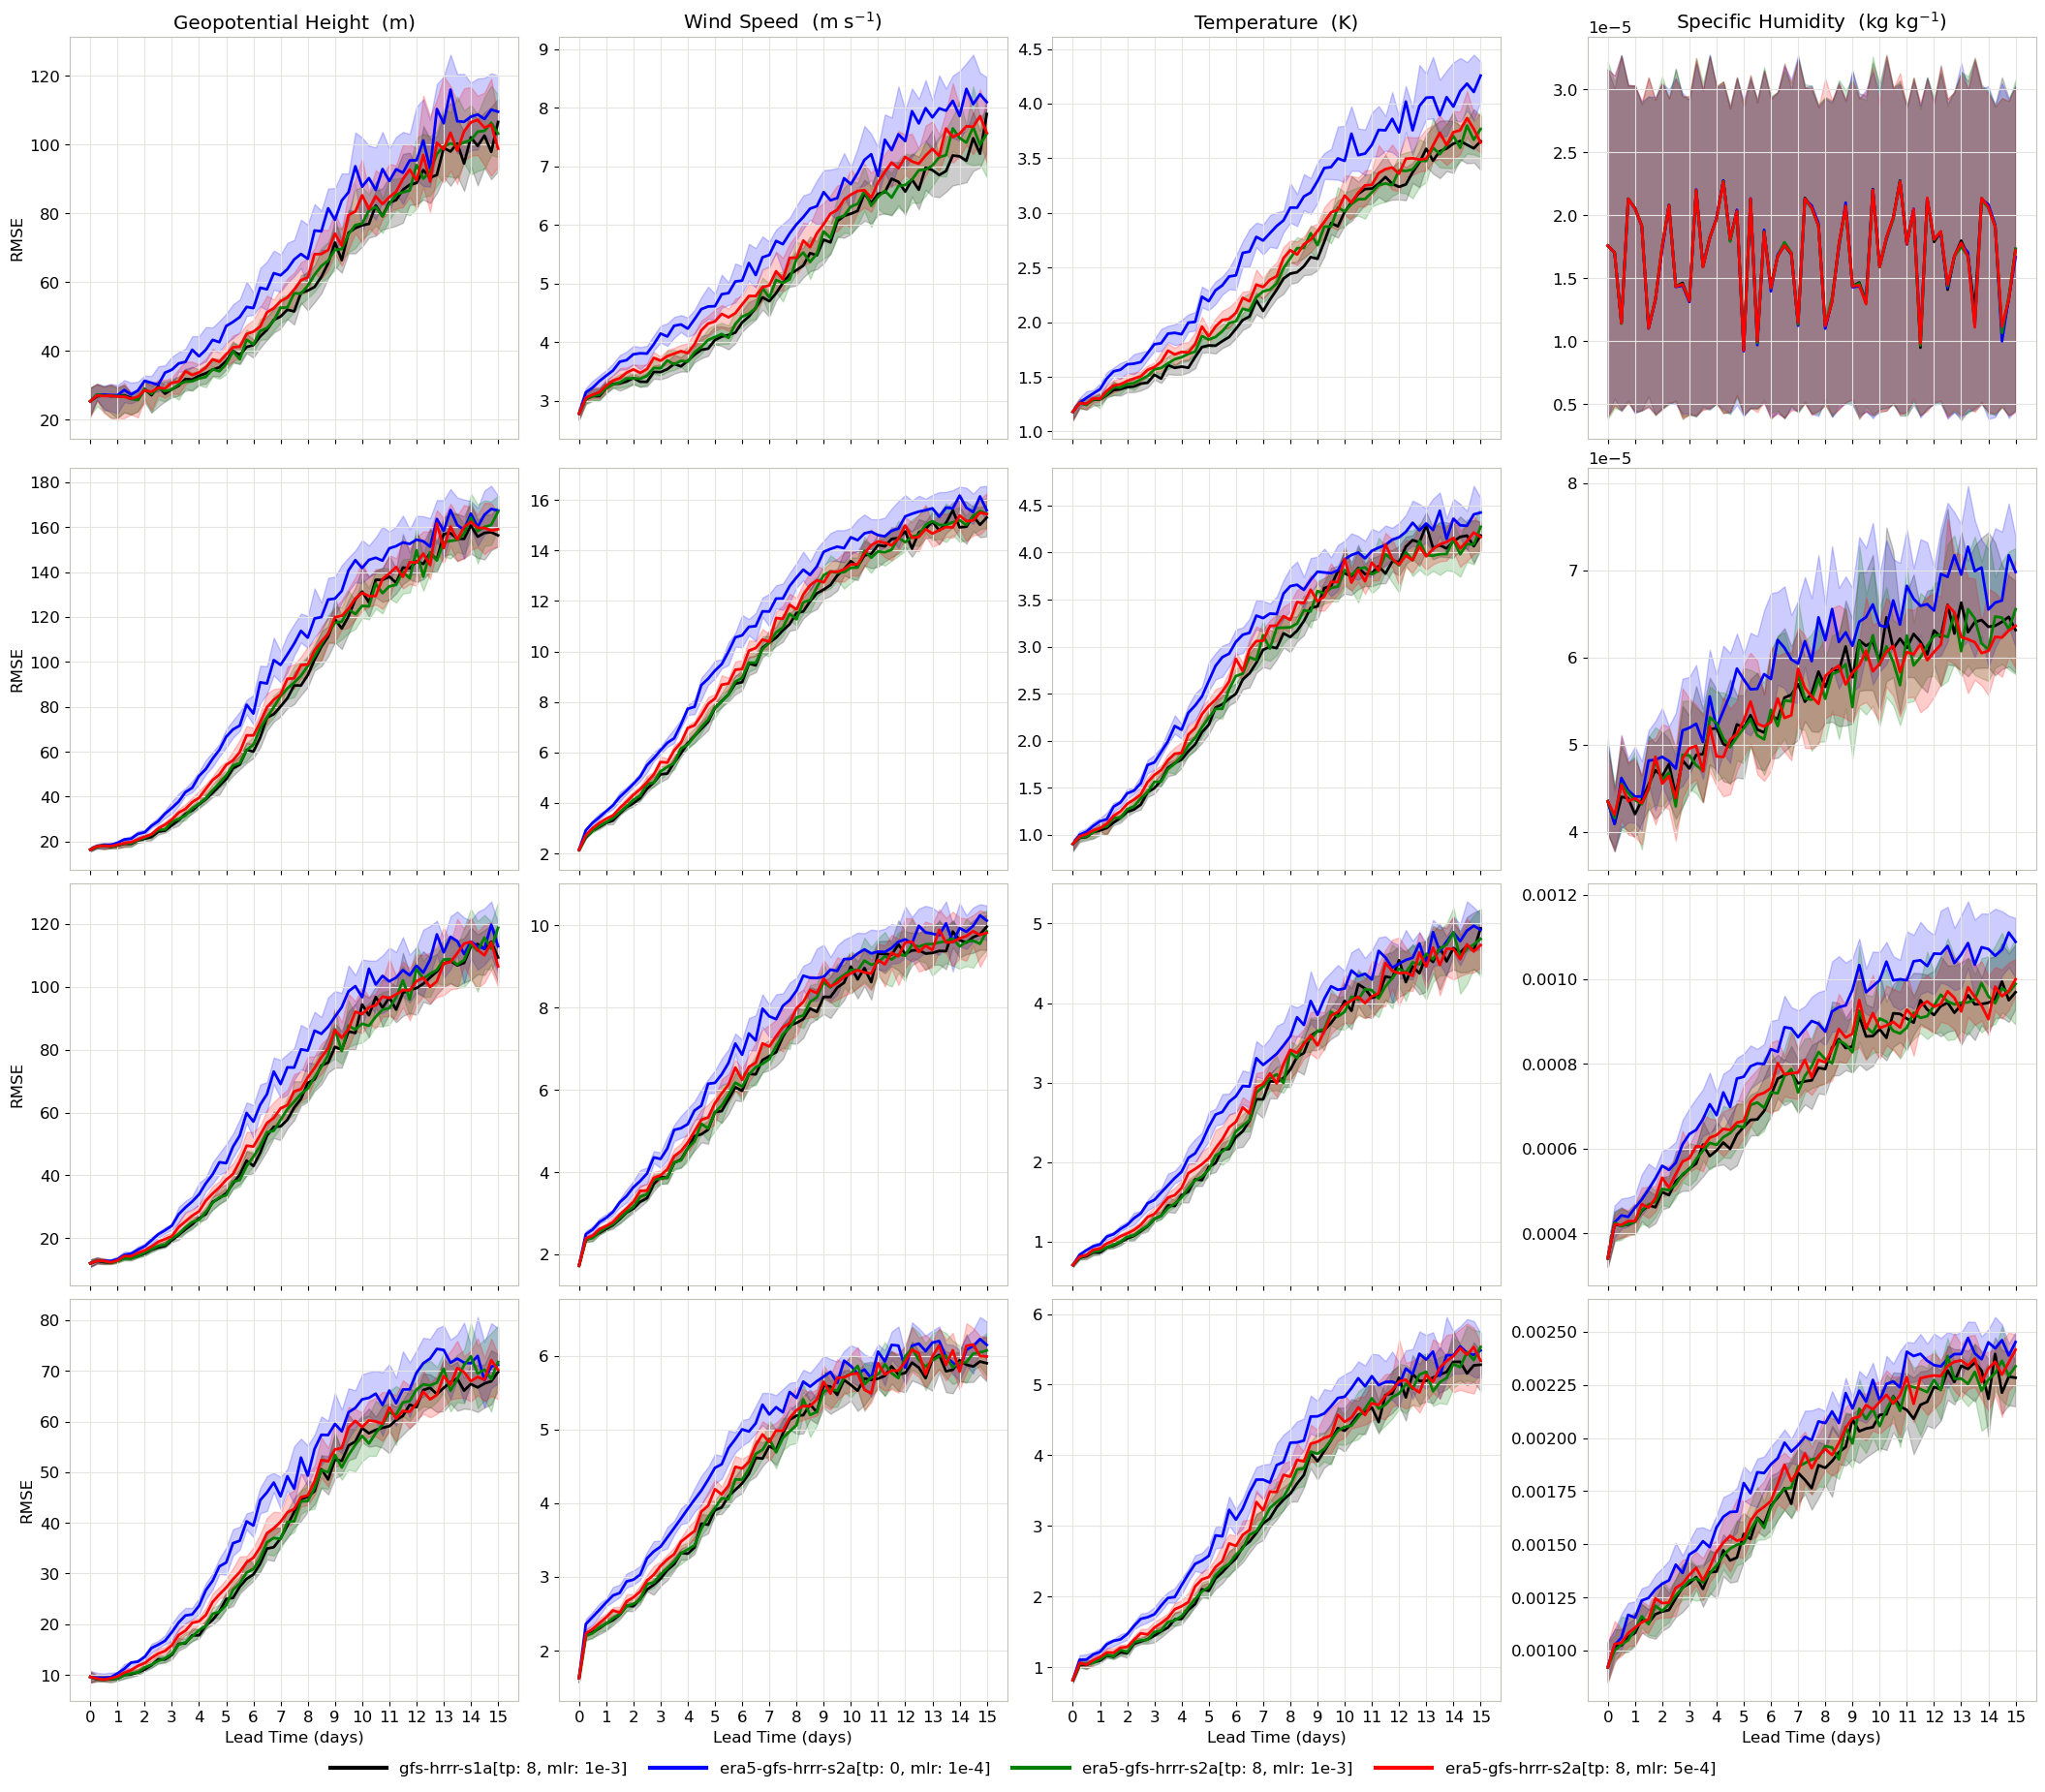

In [20]:
fig, axs = plot_level_vars(rmse, metric_name="RMSE", level_vars=LEVEL_VARS)

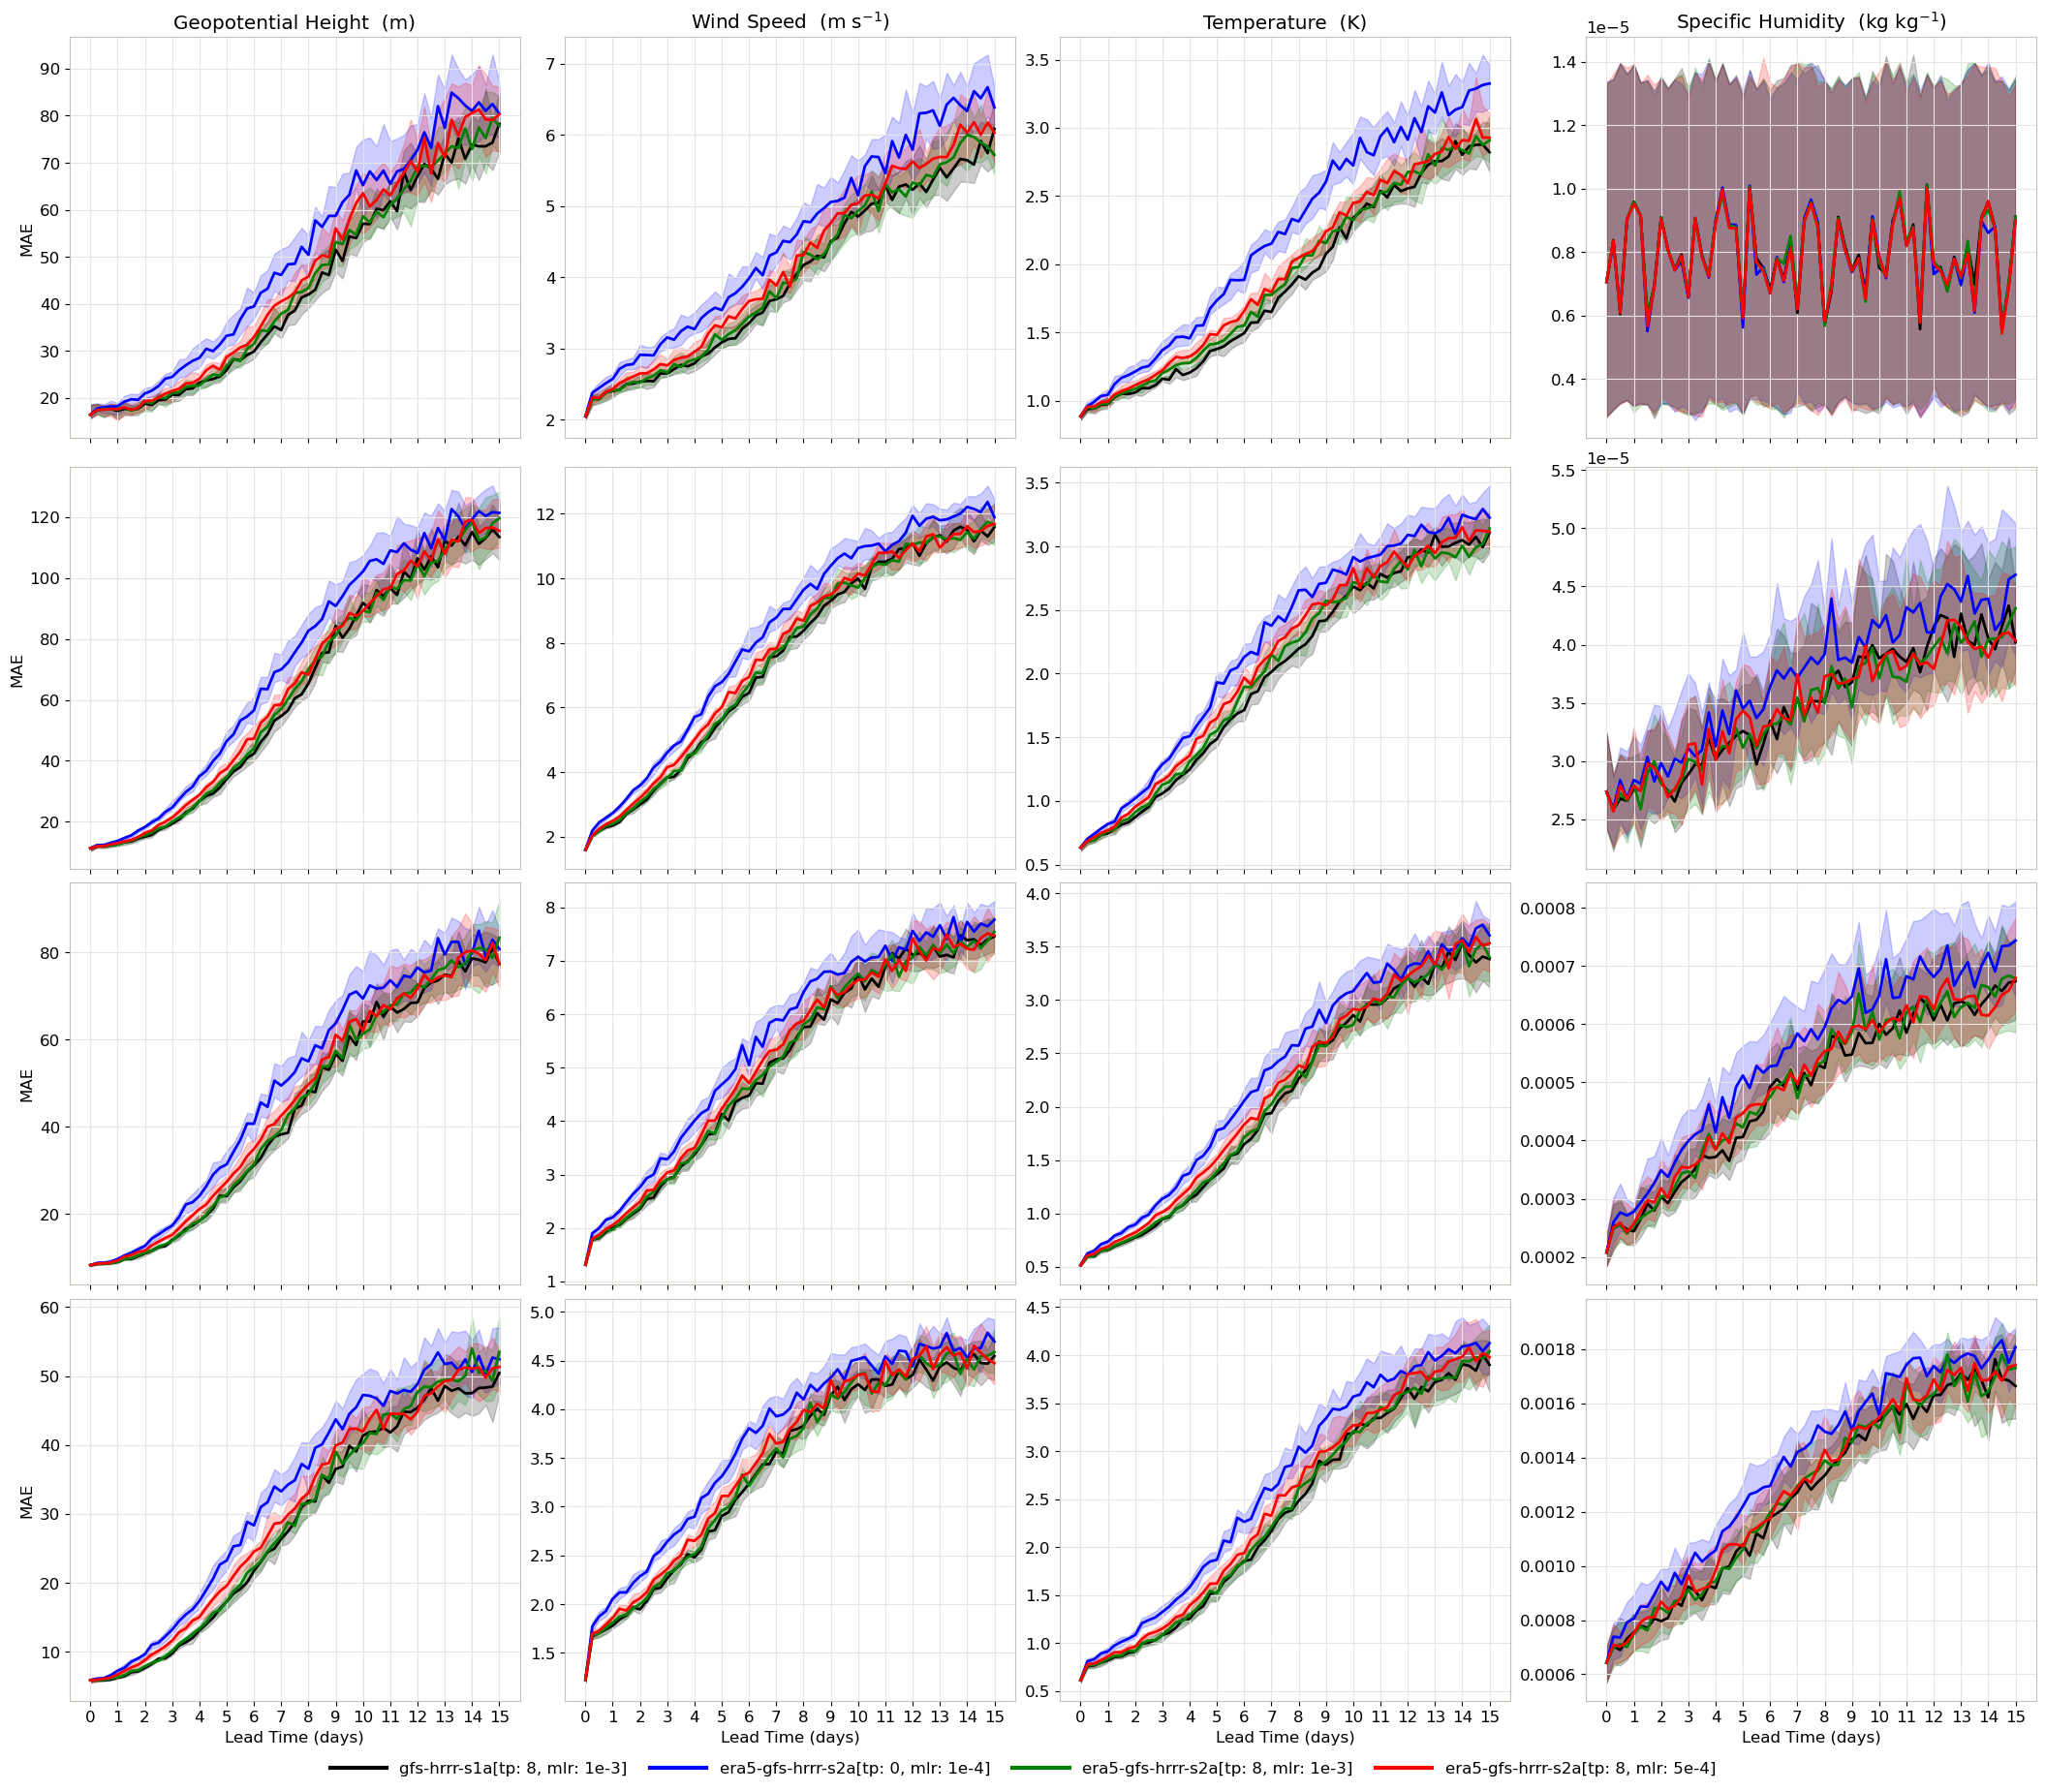

In [21]:
fig, axs = plot_level_vars(mae, metric_name="MAE", level_vars=LEVEL_VARS)

## Variables the ERA5 stage-1 runs do not carry

`geopotential_height` and `2m_specific_humidity` are missing only from
`era5-gfs-hrrr 1a` and `era5-gfs-hrrr 1b`. Every other run has them, so this section plots
the remaining nine. Each variable is paired with one all eleven share, so the panel geometry
stays valid.


Text(0.5, 1.005, 'Runs carrying the full variable set — RMSE, pressure levels')

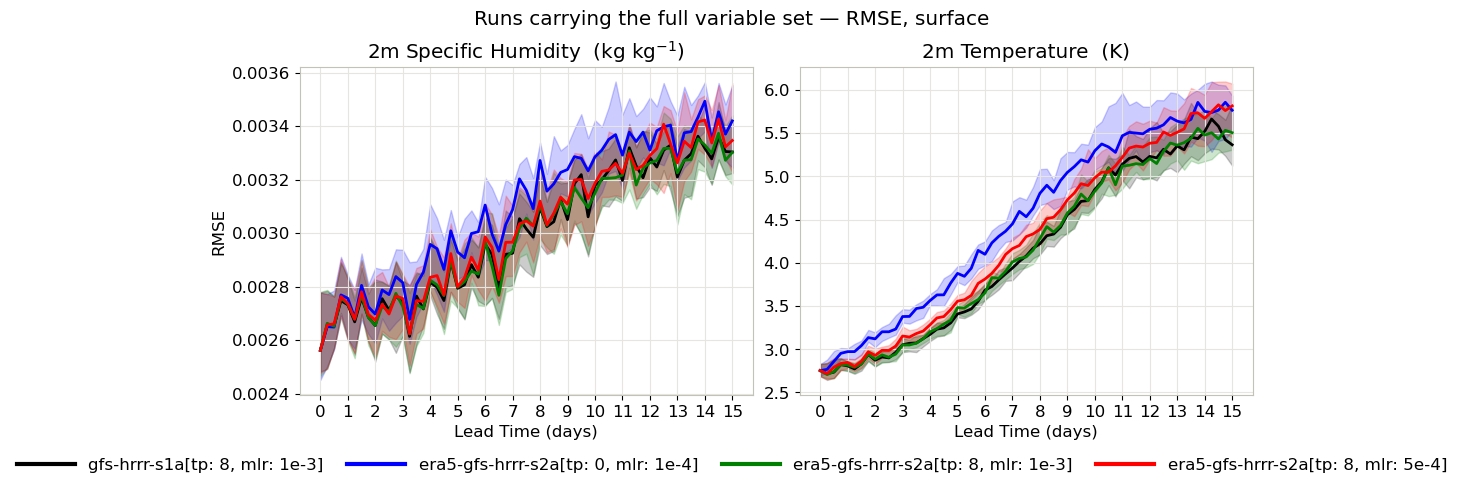

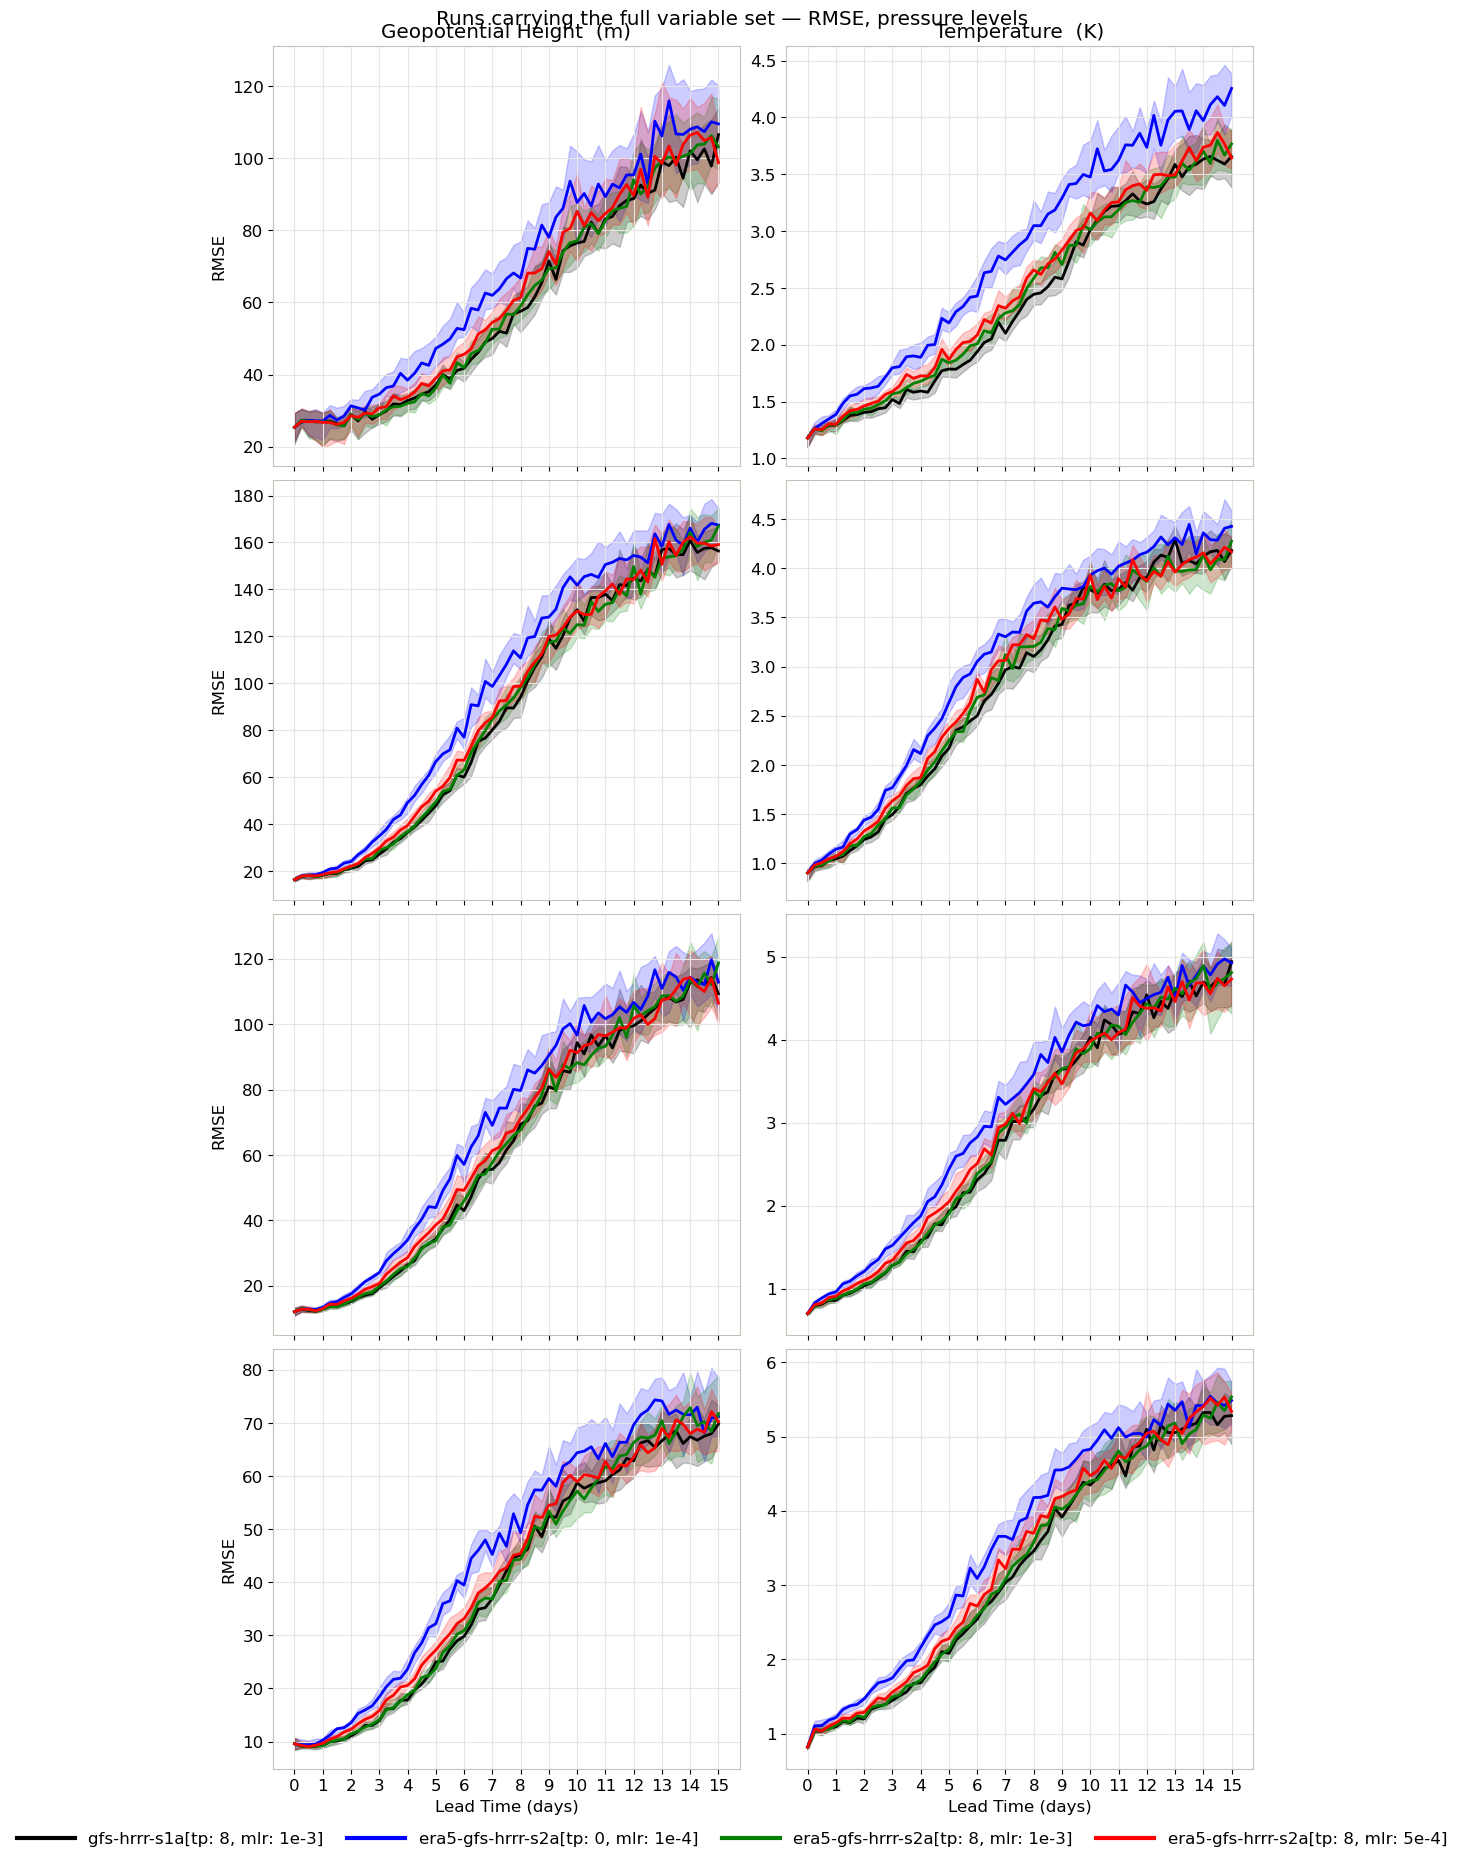

In [22]:
rmse_full = load("rmse", experiments=FULL_VARSET)

fig, axs = plot_surface_vars(
    rmse_full, metric_name="RMSE", surface_vars=("2m_specific_humidity", "2m_temperature")
)
fig.suptitle("Runs carrying the full variable set — RMSE, surface", y=1.06)

fig, axs = plot_level_vars(
    rmse_full, metric_name="RMSE", level_vars=("geopotential_height", "temperature")
)
fig.suptitle("Runs carrying the full variable set — RMSE, pressure levels", y=1.005)


## Table view

The numbers behind the curves at a few lead times — this is also what makes the three
lower-contrast series readable without relying on color.

In [23]:
import pandas as pd

def summary_table(dsdict, varname, fhrs=(0, 24, 72, 120, 240, 360), level=None, stat="median"):
    rows = {}
    for label, ds in dsdict.items():
        if varname not in ds.data_vars:
            continue
        da = ds[varname]
        if level is not None:
            da = da.sel(level=level)
        reduced = da.median("t0") if stat == "median" else da.mean("t0")
        rows[label] = reduced.sel(fhr=list(fhrs)).to_series()
    df = pd.DataFrame(rows)
    df.index.name = "fhr"
    return df

print("RMSE 2m_temperature (K), median over inits")
display(summary_table(rmse, "2m_temperature").round(3))

print("\nRMSE temperature @ 500 hPa (K), median over inits")
display(summary_table(rmse, "temperature", level=500).round(3))

RMSE 2m_temperature (K), median over inits


,"gfs-hrrr-s1a[tp: 8, mlr: 1e-3]","era5-gfs-hrrr-s2a[tp: 0, mlr: 1e-4]","era5-gfs-hrrr-s2a[tp: 8, mlr: 1e-3]","era5-gfs-hrrr-s2a[tp: 8, mlr: 5e-4]"
fhr,,,,
0,2.753,2.753,2.753,2.753
24,2.807,2.972,2.816,2.848
72,3.052,3.378,3.050,3.153
120,3.408,3.877,3.482,3.556
240,4.849,5.296,4.829,4.984
360,5.365,5.764,5.504,5.814



RMSE temperature @ 500 hPa (K), median over inits


,"gfs-hrrr-s1a[tp: 8, mlr: 1e-3]","era5-gfs-hrrr-s2a[tp: 0, mlr: 1e-4]","era5-gfs-hrrr-s2a[tp: 8, mlr: 1e-3]","era5-gfs-hrrr-s2a[tp: 8, mlr: 5e-4]"
fhr,,,,
0,0.703,0.703,0.703,0.703
24,0.859,0.963,0.883,0.910
72,1.281,1.522,1.285,1.345
120,1.936,2.440,1.903,2.048
240,4.028,4.183,3.889,3.981
360,4.940,4.922,4.808,4.728


## Save every figure, for all subregions

Writes to `figures/` next to this notebook. Same figures as above, one set per subregion.

In [24]:
def save_all(subregions=SUBREGIONS, metrics=("rmse", "mae"), figdir=FIGDIR):
    for subregion in subregions:
        data = {m: load(m, subregion=subregion) for m in metrics}
        svars = common_vars(data[metrics[0]], SURFACE_CANDIDATES)
        lvars = common_vars(data[metrics[0]], LEVEL_CANDIDATES)
        tag = f"global{subregion}"

        for metric in metrics:
            name = metric.upper()

            if metric == "rmse":
                fig, _ = plot_surface_vars(data[metric], metric_name=name,
                                           surface_vars=svars, estimator="mean")
                fig.savefig(f"{figdir}/{tag}_surface_{metric}_mean.jpeg", dpi=300, bbox_inches="tight")
                plt.close(fig)

            fig, _ = plot_surface_vars(data[metric], metric_name=name, surface_vars=svars)
            fig.savefig(f"{figdir}/{tag}_surface_{metric}.jpeg", dpi=300, bbox_inches="tight")
            plt.close(fig)

            fig, _ = plot_level_vars(data[metric], metric_name=name, level_vars=lvars)
            fig.savefig(f"{figdir}/{tag}_plevel_{metric}.jpeg", dpi=300, bbox_inches="tight")
            plt.close(fig)

        for dsdict in data.values():
            for ds in dsdict.values():
                ds.close()
        print(f"wrote {tag}")


save_all()

wrote global
wrote global.northern_hemisphere
wrote global.southern_hemisphere
wrote global.tropics
wrote global.conus
wrote global.europe
